# Demo: GA vs BPSO vs Random Search

Menjalankan konfigurasi terbaik ketiga algoritma pada satu instance, iterasi per iterasi, dengan seed dan budget yang sama seperti notebook percobaan. Yang ditampilkan:

- kurva konvergensi (gap ke optimum brute-force) yang bergerak
- alokasi dieset ke mesin dari solusi terbaik tiap algoritma, dibanding optimum
- beban tiap mesin terhadap kapasitas
- tabel cost, gap, evaluasi, dan waktu

In [1]:
import sys
import time
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "data").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
from IPython.display import display
from matplotlib.animation import PillowWriter

from src.evaluation.demo import Demo
from src.paths import FIGURES_DIR

## Parameter

In [2]:
INSTANCE = 19     # 3 | 9 | 13 | 16 | 18 | 19
SEED = None       # None = seed pertama dari master seed 2026
BUDGET = 5000     # max_evaluations, sama dengan notebook percobaan
STEP = 50         # evaluasi per frame animasi
DELAY = 0.05      # jeda antar frame (detik)

## Jalankan Demo

instance 19 dieset, seed 1829338324, optimum brute-force 6,112,960.59


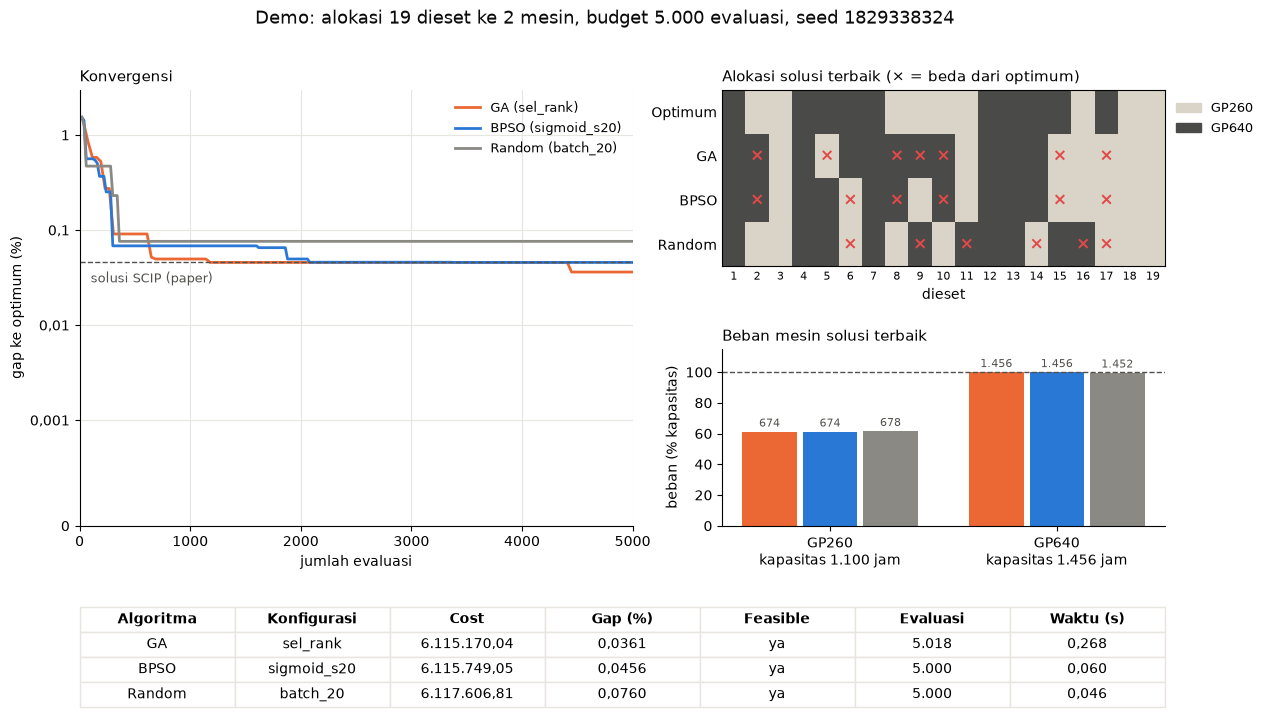

In [3]:
demo = Demo(INSTANCE, seed=SEED, budget=BUDGET, step=STEP)
print(f"instance {INSTANCE} dieset, seed {demo.seed}, optimum brute-force {demo.opt_cost:,.2f}")

handle = display(demo.fig, display_id=True)
plt.close(demo.fig)   # cegah gambar tampil dua kali
for _ in demo.frames():
    handle.update(demo.fig)
    time.sleep(DELAY)

## Ringkasan

In [4]:
demo.summary().round(4)

,algoritma,konfigurasi,cost,gap_pct,feasible,evaluasi,evaluasi_sampai_terbaik,waktu_sec
0,GA,sel_rank,6.115170e+06,0.0361,True,5018,4448,0.2679
1,BPSO,sigmoid_s20,6.115749e+06,0.0456,True,5000,3380,0.0600
2,Random,batch_20,6.117607e+06,0.0760,True,5000,360,0.0463


## Simpan Animasi (opsional)

Untuk bahan video demo cadangan.

In [5]:
out = FIGURES_DIR / "demo" / f"demo_{INSTANCE}_diesets.gif"
out.parent.mkdir(parents=True, exist_ok=True)

recording = Demo(INSTANCE, seed=SEED, budget=BUDGET, step=STEP)
writer = PillowWriter(fps=round(1 / DELAY))
with writer.saving(recording.fig, out, dpi=90):
    for _ in recording.frames():
        writer.grab_frame()
plt.close(recording.fig)
print("disimpan ke", out.relative_to(ROOT))

disimpan ke exp_results/figures/demo/demo_19_diesets.gif
